# `Материалы кафедры ММП факультета ВМК МГУ. Введение в глубокое обучение.`

## `Задание 02. Сегментация изображений`

#### Фамилия, имя: Комлева Анна

Дата выдачи: <span style="color:red">__13 марта__</span>.

Мягкий дедлайн: <span style="color:red">__29 марта 3:00__</span>.

Стоимость: __10 баллов__ (основная часть заданий) + __4.25 балла__ (дополнительные задания).

<span style="color:red">__В ноутбуке все клетки должны выполняться без ошибок при последовательном их выполнении.__</span>

#### `Москва, 2026`

В этом задании вы будете решать задачу сегментации людей на фотографии с помощью нейросетевых архитектур `U-Net` и `LinkNet`.

Данные для выполнения задания можно скачать по [ссылке](https://disk.yandex.ru/d/tI6d3LBMHTwOnw).

## `Загрузка данных (1 балл)`

Для загрузки данных pytorch опирается на такую сущность, как **`Dataset`**.

Этот абстрактный класс определен в `torch.utils.data.dataset`:

```python
class Dataset(object):
    """An abstract class representing a Dataset.

    All other datasets should subclass it. All subclasses should override
    ``__len__``, that provides the size of the dataset, and ``__getitem__``,
    supporting integer indexing in range from 0 to len(self) exclusive.
    """

    def __getitem__(self, index):
        raise NotImplementedError

    def __len__(self):
        raise NotImplementedError

    def __add__(self, other):
        return ConcatDataset([self, other])
```
При определении нового источника данных мы создаем наследника данного класса и реализуем методы `__getitem__` и `__len__`.

Пример готового такого класса — `torchvision.datasets.ImageFolder`, который позволяет создать датасет на основе директории с ImageNet-подобной структурой поддиректорий (`./train/{class}` и `./val/{class}`):

```python
imagenet = torchvision.datasets.ImageFolder('path/to/imagenet_root/')
```

Реализуйте класс `PhotosDataset` для выданных данных.

**Внимание.** Возможно, стоит прочитать следующий пункт задания, чтобы реализация была удобной.

In [ ]:
import os

import numpy as np
import numpy.testing as npt

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.models import vgg13, VGG13_Weights
import torch.nn.functional as F

import matplotlib_inline
import matplotlib.pyplot as plt

import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm

%matplotlib inline
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

In [ ]:
from PIL import Image, ImageDraw, ImageEnhance

In [ ]:
class PhotosDataset(Dataset):
    def __init__(self, images_dir, target_dir=None, transforms=None):
        """
        Arguments
        ---------
        images_dir : str
            Path to directory with images

        target_dir : str
            Path to directory with masks.
            Each mask corresponds to one image.
            Corresponding mask and image have the same name, but different format.

        transforms : some collection
            Sequence of transformations for images and masks.
        """
        self.images_dir = images_dir
        self.target_dir = target_dir
        self.transforms = transforms

        self.images = sorted([img for img in os.listdir(images_dir)])
        self.targets = None
        if self.target_dir is not None:
          self.targets = sorted([tgt for tgt in os.listdir(target_dir)])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        """
        Arguments
        ---------
        idx : int
            Index of image and mask

        Returns
        -------
        (image, mask)
        """
        image_name = self.images[idx]
        image = Image.open(os.path.join(self.images_dir, image_name)).convert('RGB')

        mask = None
        if self.targets is not None:
            target_name = self.targets[idx]
            mask = Image.open(os.path.join(self.target_dir, target_name)).convert('L')

        if self.transforms is not None:
            for t in self.transforms:
                if isinstance(t, (HorizontalFlip, FragmentCutting, BrightnessChange, BackgroundChange)):
                    image, mask = t(image, mask)
                else:
                    image = t(image)
                    if isinstance(t, transforms.ToTensor):
                        mask = transforms.ToTensor()(mask)

        if mask is not None and not isinstance(mask, torch.Tensor):
            mask = transforms.ToTensor()(mask)

        return image, mask

## `Модуль аугментации (2 балла)`

Конструктор стандартного `ImageFolder`, принимает параметр `transform` (и иногда `target_transform`).

Они служат для того, чтобы загружаемые изображения (обычно это `PIL.Image`) или таргеты преобразовывать в тензоры нужного вида.

В `torchvision` входит модуль `transforms` для стандартных примеров таких преобразований. В `transforms` могут содержаться случайные преобразования, это самый простой путь для реализации аугментации данных.

При определении кастомного трансформера помимо конструктора нужно реализовать лишь метод `__call__`:

```python
class HorizontalFlip(object):
    def __init__(self, mode=0):
        self.method = mode

    def __call__(self, img):
        """
        Args:
            img (PIL.Image): Image to be flipped.

        Returns:
            PIL.Image: Randomly flipped image.
        """
        if self.method:
            return img.transpose(Image.FLIP_LEFT_RIGHT)
        return img

```

С полным списком стандартных преобразований можно ознакомиться в [документации](https://pytorch.org/vision/0.12/transforms.html).

В данной части вам предлагается самостоятельно реализовать несколько кастомных трансформеров.
Обратите внимание, что для некоторых трансформеров, необходимо преобразовывать и изображение, и маску, а для каких-то только изображение.

Один из путей реализации:
* реализовать декоратор, делающий любое преобразование случайным
* реализовать декоратор, применяющий преобразование и к изображению, и к маске

Список трансформеров, которые надо реализовать:

1. случайное (с вероятностью $p$) горизонтальное отображение (flip) изображения
2. случайное (с вероятностью $p$) вырезание фрагмента изображения (заданного или случайного размера)
3. случайное (с вероятностью $p$) изменение яркости изображения (на заданную или случайную величину)
4. случайное (с вероятностью $p$) изменение фона изображения (на изображение из заданного списка изображений)

Используйте разумные пределы для аугментаций. Одной из причин плохого обучения модели могут быть слишком сильные аугментации. Визуально убедитесь, что граничные случаи достаточно адекватны задаче.

Обратите внимание, что под вырезанием фрагмента подразумевается вырезания части изображения из исходного, то есть вырезание какой-то части изображения (создание отверстий в изображении). Если после слоя вырезания размеры изображения поменялись, то вы неправильно реализовали модуль. Это преобразование известно как [RandomErasing](https://docs.pytorch.org/vision/main/generated/torchvision.transforms.RandomErasing.html).

**Внимание.** Вы должны самостоятельно реализовать аугментации, а не использовать готовые функции.

*Примечание:* В аугментации 4, вы сами выбираете какой фон, достаточно 10 изображений найденных из любых источников, которые можно назвать фоном. В аугментациях 2 и 3 подразумевается реализация и заданной величины и константы, код должен уметь обрабатывать оба случая.

Трансформер №1: случайное (с вероятностью $p$) горизонтальное отображение (flip) изображения

In [ ]:
class HorizontalFlip (object):
  def __init__ (self, prob=0.5):
    self.prob = prob

  def __call__(self, img, mask):
    if self.prob >= np.random.uniform(0, 1):
      return img.transpose(Image.FLIP_LEFT_RIGHT), mask.transpose(Image.FLIP_LEFT_RIGHT)
    return img, mask

Трансформер №2: случайное (с вероятностью $p$) вырезание фрагмента изображения (заданного или случайного размера)

In [ ]:
class FragmentCutting(object):
  def __init__(self, prob=0.5, size=None):
    self.prob = prob
    self.size = size

  def __call__(self, img, mask):
    if self.prob <= np.random.uniform(0, 1):
      return img, mask

    img_width, img_height = img.size
    img = img.copy()
    draw = ImageDraw.Draw(img)
    if self.size is None:
      width, height = np.random.uniform(0.1*img_width, 0.3*img_width), np.random.uniform(0.1*img_height, 0.3*img_height)
    else:
      width, height = self.size

    x1, y1 = (int(np.random.uniform(0, img_width - width)), int(np.random.uniform(0, img_height - height)))
    x2, y2 = x1 + width, y1 + height

    color = (128, 128, 128)

    draw.rectangle([x1, y1, x2, y2], fill=color)

    return img, mask


Трансформер №3: случайное (с вероятностью $p$) изменение яркости изображения (на заданную или случайную величину)

In [ ]:
import random

class BrightnessChange(object):
  def __init__(self, prob=0.5, level=None):
    self.prob = prob
    self.level = level

  def __call__(self, img, mask):
    if self.prob <= random.random():
      return img, mask

    if self.level is not None:
      factor = 1 + self.level
    else:
      factor = 1 + np.random.uniform(-0.5, 0.5)

    enhancer = ImageEnhance.Brightness(img)
    return enhancer.enhance(factor), mask


Трансформер №4: случайное (с вероятностью $p$) изменение фона изображения (на изображение из заданного списка изображений)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

bg_folder = '/content/drive/MyDrive/Картинки/'
background_paths = [os.path.join(bg_folder, f) for f in os.listdir(bg_folder) if f.endswith(('.jpg', '.png'))]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
class BackgroundChange(object):
  def __init__(self, prob=0.5, images_path=background_paths):
    self.prob = prob
    self.backs = [Image.open(path).convert('RGB') for path in images_path]

  def __call__(self, img, mask):
    if random.random() >= self.prob:
      return img, mask

    current_back = random.choice(self.backs)
    current_back = current_back.resize(img.size)

    img_np = np.array(img).astype(np.float32)
    mask_np = np.array(mask).astype(np.float32) / 255.0
    back_np = np.array(current_back).astype(np.float32)

    result_np = img_np * mask_np[..., np.newaxis] + back_np * (1 - mask_np[..., np.newaxis])
    result_np = np.clip(result_np, 0, 255).astype(np.uint8)

    img = Image.fromarray(result_np)

    return img, mask

Добавьте случайные преобразования в ваши датасеты. Также, добавьте преобразование в tensor и нормализацию для изображения:

```python
transforms.ToTensor()
transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)
```

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from torchvision import transforms

DATA_PATH = '/content/drive/MyDrive/people_data/'


train_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'train'),
    target_dir=os.path.join(DATA_PATH, 'train_mask'),
    transforms= [
    HorizontalFlip(prob=0.5),
    FragmentCutting(prob=0.2),
    BrightnessChange(prob=0.3),
    BackgroundChange(prob=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])]
)

test_dataset = PhotosDataset(
    images_dir=os.path.join(DATA_PATH, 'test'),
    target_dir=os.path.join(DATA_PATH, 'test_mask'),
    transforms= [
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])]
)

Функция для отображения изображения:

In [ ]:
def show_idx_image(dataset, idx):
    image, mask = dataset[idx]

    image = image.permute(1, 2, 0).numpy()
    image = (image * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    mask = mask.squeeze(0).numpy()

    fig, axes = plt.subplots(1, 2, figsize=(6, 4))

    axes[0].imshow(image)
    axes[1].imshow(mask)

    axes[0].set_axis_off()
    axes[1].set_axis_off()

    fig.tight_layout()
    plt.show()

Отобразите несколько изображений и масок, на которых будет видна правильная работа вашего модуля аугментации данных. Необходимо проверить каждый модуль аугментации отдельно, в ином случае будут сниматься баллы.

**Важно:** Проверьте корректность работы модулей, действительно ли маска изображения корректна для изображения после аугментации.

Функция для проверки модулей аугментации (переписала show_idx_image, потому что так удобнее)

In [ ]:
def check_augmentation(image_paths, mask_paths, transform, n=5):
    if isinstance(image_paths, str):
        image_paths = [image_paths]
        mask_paths = [mask_paths]

    for image_path, mask_path in zip(image_paths, mask_paths):
        img = Image.open(image_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')

        fig, axes = plt.subplots(n, 3, figsize=(9, n * 3))
        fig.suptitle(f'Файл: {os.path.basename(image_path)}', fontsize=12)

        if n == 1:
            axes = [axes]

        for i in range(n):
            aug_img, aug_mask = transform(img, mask)

            axes[i][0].imshow(img)
            axes[i][0].set_title(f'Оригинал {i+1}')
            axes[i][0].axis('off')

            axes[i][1].imshow(aug_img)
            axes[i][1].set_title(f'Аугментация {i+1}')
            axes[i][1].axis('off')

            axes[i][2].imshow(aug_mask, cmap='gray')
            axes[i][2].set_title(f'Маска аугментированная {i+1}')
            axes[i][2].axis('off')

        fig.tight_layout()
        plt.show()

import random

def sample_paths(images_dir, masks_dir, k=3):
    names = random.sample(os.listdir(images_dir), k)
    image_paths = [os.path.join(images_dir, name) for name in names]
    mask_paths = [os.path.join(masks_dir, os.path.splitext(name)[0] + '.png') for name in names]
    return image_paths, mask_paths

Трансформер №1

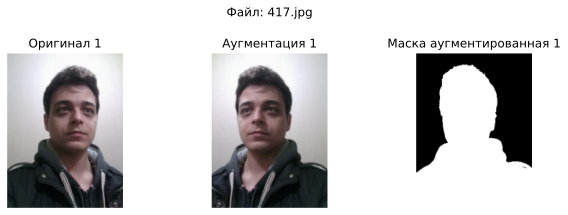

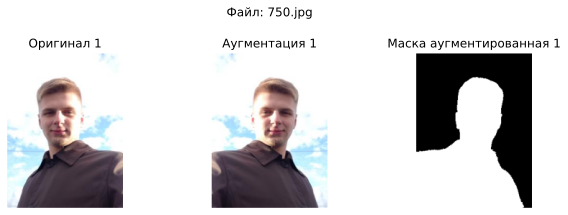

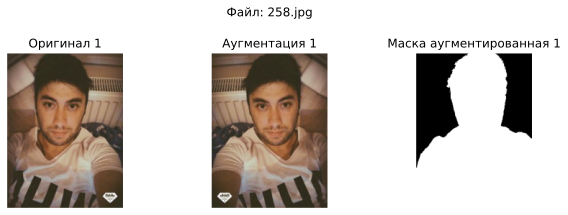

In [ ]:
image_paths, mask_paths = sample_paths(
    '/content/drive/MyDrive/people_data/train',
    '/content/drive/MyDrive/people_data/train_mask',
    k=3
)

check_augmentation(image_paths, mask_paths, transform=HorizontalFlip(prob=1.0), n=1)

Трансформер №2

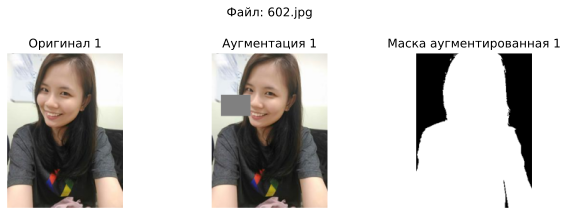

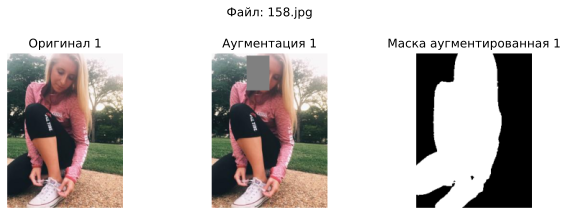

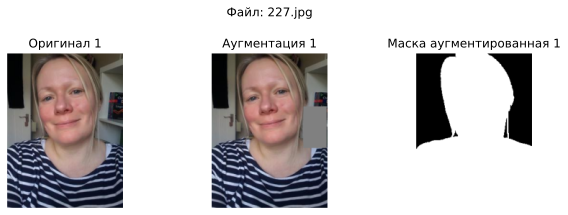

In [ ]:
image_paths, mask_paths = sample_paths(
    '/content/drive/MyDrive/people_data/train',
    '/content/drive/MyDrive/people_data/train_mask',
    k=3
)

check_augmentation(image_paths, mask_paths, transform=FragmentCutting(prob=1.0), n=1)

Трансформер №3

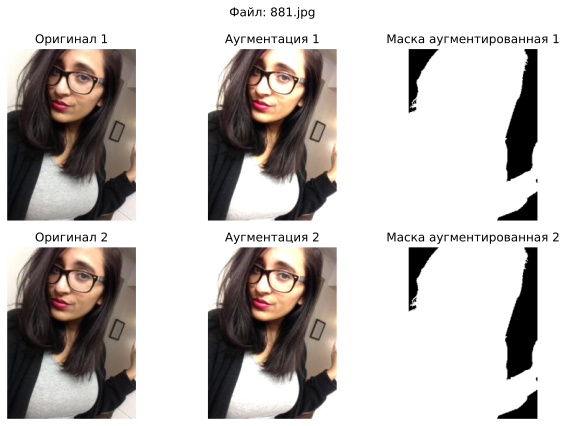

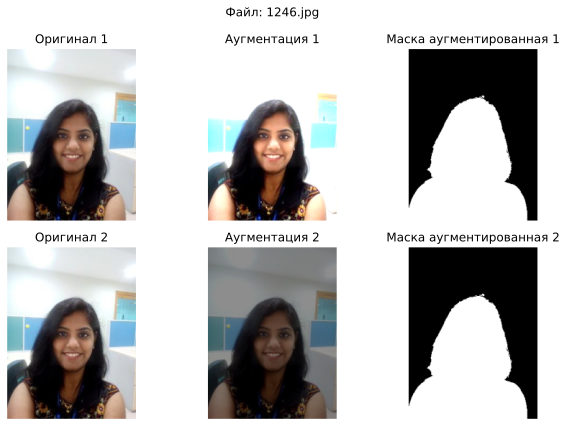

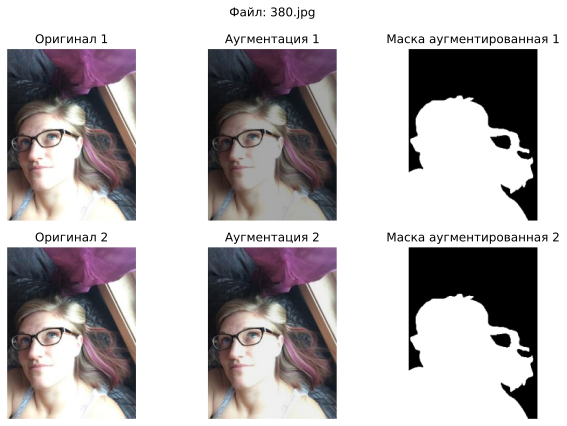

In [ ]:
image_paths, mask_paths = sample_paths(
    '/content/drive/MyDrive/people_data/train',
    '/content/drive/MyDrive/people_data/train_mask',
    k=3
)

check_augmentation(image_paths, mask_paths, transform=BrightnessChange(prob=1.0), n=2)

Трансформер №4

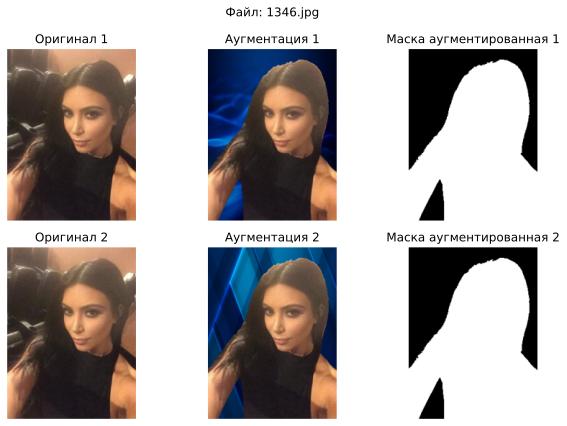

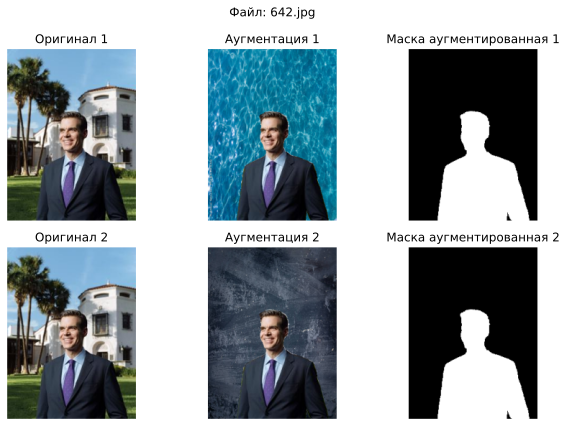

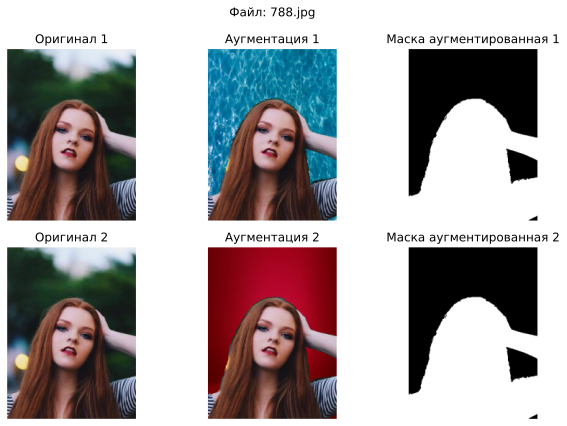

In [ ]:
image_paths, mask_paths = sample_paths(
    '/content/drive/MyDrive/people_data/train',
    '/content/drive/MyDrive/people_data/train_mask',
    k=3
)

check_augmentation(image_paths, mask_paths, transform=BackgroundChange(prob=1.0), n=2)

## `Загрузчики`

При обучении сети удобнее работать не с датасетами, а с загрузчиками. Загрузчики создаются на основе датасета и позволяют итерироваться по батчам из него.

Обратите внимание на параметры `DataLoader`. При `num_workers`$\;> 1$, батчи готовятся (загружаются картинки, обрабатываются и так далее) сразу в нескольких фоновых процессах. С помощью параметра `shuffle` можно подавать картинки на обучение в случайном порядке.

Обычно, скорость обработки данных на GPU превышает скорость загрузки данных в одном процессе, поэтому типичное значение для `num_workers`$\approx 3\text{-}10$.

Учтите, что на некоторых системах в Jupyter Notebook при `num_workers`$>0$ `DataLoader` перестаёт работать. В таком случае установите это значение в $0$.

In [ ]:
test_data_loader = DataLoader(test_dataset, batch_size=8, num_workers=3)
train_data_loader = DataLoader(train_dataset, batch_size=8, num_workers=3, shuffle=True)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## `DiceLoss (1 балл)`

Функция потерь реализовывается как и все стандартные нейронные модули в pytorch, через `torch.nn.Module`. В ячейке ниже вам предлагается реализовать функцию потерь `dice` (аналог меры Жаккарда).

Результат **Dice Loss** определим как:

$$
\text{Dice Coefficient} = 2\frac{|A \cap B| }{|A| + |B|} \leadsto \text{Dice Loss} = 1 - \frac{2\sum\limits_{i, j}a_{ij}b_{ij}}{\sum\limits_{ij}(a_{ij} + b_{ij} + \varepsilon)}
$$

где $a_{ij} \in [0, 1]$ — предсказанная вероятность нахождения человека в пикселе изображения, $b_{ij}$ — истинная разметка для пикселя изображения.

In [ ]:
class DiceLoss(torch.nn.Module):
    def __init__(self, eps=1e-7, reduction=None, with_logits=True):
        """
        Arguments
        ---------
        eps : float
            eps in denominator
        reduction : Optional[str] (None, 'mean' or 'sum')
            specifies the reduction to apply to the output:

            None: no reduction will be applied
            'mean': the sum of the output will be divided by the number of elements in the batch
            'sum':  the output will be summed.
        with_logits : bool
            If True, use additional sigmoid for inputs
        """
        super().__init__()
        self.eps = eps
        self.reduction = reduction
        self.with_logits = with_logits

    def forward(self, logits, true_labels):
        """
        Arguments
        ---------
        logits: torch.Tensor
            Unnormalized probability of true class. Shape: [B, ...]
        true_labels: torch.Tensor
            Mask of correct predictions. Shape: [B, ...]
        Returns
        -------
        torch.Tensor
            If reduction is 'mean' or 'sum' returns a tensor with a single element
            Otherwise, returns a tensor of shape [B]
        """
        true_labels = true_labels.to(torch.long)

        if self.with_logits:
            logits = torch.sigmoid(logits)

        log_size = logits.size(0)
        logits_flat = logits.view(log_size, -1)
        true_flat = true_labels.view(log_size, -1)

        dice = 1 - (2*(logits_flat*true_flat).sum(dim=1)/((logits_flat + true_flat).sum(dim=1) + self.eps))

        if self.reduction == 'sum':
            loss_value = dice.sum()
        elif self.reduction == 'mean':
            loss_value = dice.mean()
        elif self.reduction is None:
            loss_value = dice

        return loss_value

Проверка реализации:

In [ ]:
logits = torch.tensor([
    [[0, 0.5], [0.5, 1]],
    [[0.1, 0.1], [0, 0]],
])

target = torch.tensor([
    [[0, 1], [1, 1]],
    [[1, 0], [0, 1]],
])

losses = DiceLoss(with_logits=False, reduction=None, eps=1e-7)(logits, target)
npt.assert_almost_equal(losses.numpy(), np.array([0.2, 0.90909]), decimal=4)

loss = DiceLoss(with_logits=False, reduction='mean', eps=1e-7)(logits, target)
npt.assert_almost_equal(float(loss.numpy()), 0.554545, decimal=4)

loss = DiceLoss(with_logits=False, reduction='sum', eps=1e-7)(logits, target)
npt.assert_almost_equal(float(loss.numpy()), 1.10909, decimal=4)

## `U-Net (3 балла)`

Для решения задачи сегментации будем использовать [U-Net](https://arxiv.org/pdf/1505.04597.pdf) с энкодером из первых блоков предобученного `VGG13`.

Концептуальная схема представлена на диаграмме ниже:

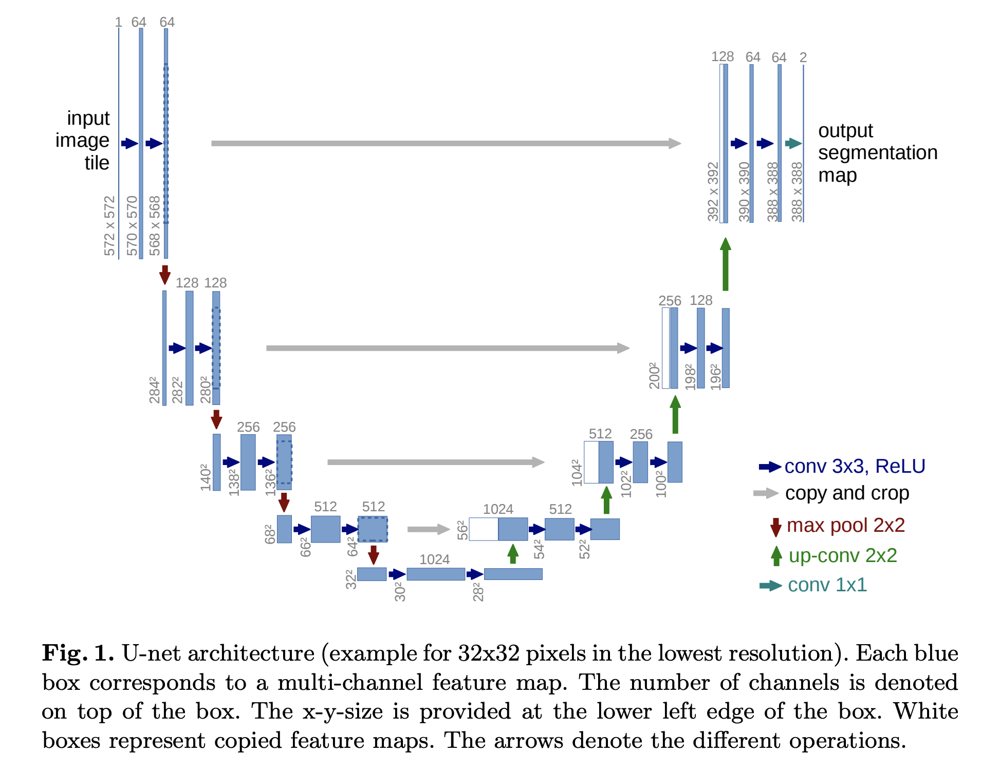

Заметим, что блоки VGG13 имеют следующий вид:
```python
    (0): Conv2d(...)
    (1): ReLU(...)
    (2): Conv2d(...)
    (3): ReLU(...)
    (4): MaxPool2d(...)
```

Для удобства, уберём слои `MaxPool2d` из блоков энкодера и будем применять pooling отдельно. Возможно, вам будет полезно вывести архитектуру модели `VGG` и изучить параметры слоев pooling.

При реализации `Decoder` вам пригодится интерполяция, для этого можно использовать `torch.nn.functional.interpolate` с `mode=nearest`.

Реализуйте архитектуру данной сети.

#### `Encoder`

In [ ]:
class VGG13Encoder(torch.nn.Module):
    def __init__(self, num_blocks, weights=VGG13_Weights.DEFAULT):
        super().__init__()
        self.num_blocks = num_blocks

        # Будем использовать предобученную VGG13 в качестве backbone
        feature_extractor = vgg13(weights=weights).features

        # Каждый блок энкодера U-Net — это блок VGG13 без MaxPool2d
        self.blocks = torch.nn.ModuleList()
        neccessary_blocks = [(0, 3), (5, 8), (10, 13), (15, 18), (20, 23)]
        for idx in range(self.num_blocks):
            # Возьмите нужные слои из `feature_extractor` для очередного U-Net блока
            # Объедините их с помощью `torch.nn.Sequential`
            start, end = neccessary_blocks[idx]
            self.blocks.append(
                torch.nn.Sequential(*list(feature_extractor.children())[start:end+1])
            )

    def forward(self, x):
        activations = []
        for idx, block in enumerate(self.blocks):
            # Примените очередной блок U-Net
            # your code here
            output = block(x)

            # Сохраните активации для передачи их в декодер
            # your code here
            activations.append(output)

            # При необходимости примените max-pool
            # Можно использовать `torch.functional.F.max_pool2d`
            # your code here
            if idx < self.num_blocks - 1:
              x = F.max_pool2d(output, kernel_size=2, stride=2)

        return activations

In [ ]:
assert sum((param.numel() for param in VGG13Encoder(num_blocks=1).parameters())) == 38720
assert sum((param.numel() for param in VGG13Encoder(num_blocks=2).parameters())) == 260160
assert sum((param.numel() for param in VGG13Encoder(num_blocks=3).parameters())) == 1145408

x = torch.arange(1 * 3 * 320 * 240).reshape(1, 3, 320, 240) / (1 * 3 * 320 * 240)
out = VGG13Encoder(num_blocks=3)(x)

assert len(out) == 3
npt.assert_almost_equal(torch.linalg.norm(out[0]).item(), 902.218, decimal=3)
npt.assert_almost_equal(torch.linalg.norm(out[1]).item(), 571.030, decimal=3)
npt.assert_almost_equal(torch.linalg.norm(out[2]).item(), 648.068, decimal=3)

Downloading: "https://download.pytorch.org/models/vgg13-19584684.pth" to /root/.cache/torch/hub/checkpoints/vgg13-19584684.pth


100%|██████████| 508M/508M [00:03<00:00, 152MB/s]


#### `Decoder`

In [ ]:
class DecoderBlock(torch.nn.Module):
    def __init__(self, out_channels):
        super().__init__()

        self.upconv = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv1 = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv2 = torch.nn.Conv2d(
            in_channels=out_channels, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.relu = torch.nn.ReLU()

    def forward(self, down, left):
        # Upsample x2 и свёртка
        # your code here
        down = F.interpolate(down, scale_factor=2, mode='nearest')
        down = self.upconv(down)

        # Конкатенация выхода энкодера и предыдущего блока декодера
        # your code here
        x = torch.cat([down, left], dim=1)

        # Две свёртки с ReLu
        # your code here
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        return x

In [ ]:
class Decoder(torch.nn.Module):
    def __init__(self, num_filters, num_blocks):
        super().__init__()

        self.blocks = torch.nn.ModuleList()
        for idx in range(num_blocks):
            self.blocks.insert(0, DecoderBlock(num_filters * 2 ** idx))

    def forward(self, acts):
        up = acts[-1]
        for block, left in zip(self.blocks, acts[-2::-1]):
            up = block(up, left)
        return up

#### `U-Net`

In [ ]:
class UNet(torch.nn.Module):
    def __init__(self, num_classes=1, num_blocks=4):
        super().__init__()
        # your code here
        self.encoder = VGG13Encoder(num_blocks=num_blocks)

        # your code here
        self.decoder = Decoder(num_blocks=num_blocks - 1, num_filters=64)

        # Свёртка 1x1 для попиксельной агрегации каналов
        # your code here
        self.final = torch.nn.Conv2d(in_channels=64, out_channels=num_classes, kernel_size=1)

    def forward(self, x):
        # your code here
        x = self.encoder(x)
        x = self.decoder(x)
        x = self.final(x)

        return x

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = UNet(num_classes=1, num_blocks=3).to(device)
x = torch.arange(1 * 3 * 320 * 240).reshape(1, 3, 320, 240) / (1 * 3 * 320 * 240)
x = x.to(device)

assert sum((param.numel() for param in model.parameters())) == 2067649
assert list(model(x).shape) == [1, 1, 320, 240]
model

cuda
Downloading: "https://download.pytorch.org/models/vgg13-19584684.pth" to /root/.cache/torch/hub/checkpoints/vgg13-19584684.pth


100%|██████████| 508M/508M [00:02<00:00, 194MB/s]


UNet(
  (encoder): VGG13Encoder(
    (blocks): ModuleList(
      (0): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
      (2): Sequential(
        (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
  )
  (decoder): Decoder(
    (blocks): ModuleList(
      (0): DecoderBlock(
        (upconv): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
       

### `Оценивание качества сети`


Обычно, оптимизируемый функционал сложно интерпретировать, а также в разных экспериментах могут использоваться разные функции потерь. Поэтому необходимо замерять и отслеживать независимую метрику качества. Предлагается использовать **IoU (Intersection over Union)** — один из стандартных вариантов для задачи сегментации:
$$
\text{IoU} = \frac{|A \cap B|}{|A \cup B|} = \frac{\sum\limits_{ij}a_{ij}b_{ij}}{\sum\limits_{ij}a_{ij} + b_{ij} - a_{ij}b_{ij}}
$$

Учтите, что знаменатель может быть равен нулю, например, если маска нулевая. Такие объекты можно не учитывать при агрегации и пропускать, так как в ином случае подсчет метрики на всем батче будет NaN. В pytorch есть встроенные для этого функции с префиксом nan.


In [ ]:
class IoUScore(torch.nn.Module):
    def __init__(self, threshold, reduction=None):
        """
        Arguments
        ---------
        threshold : float
            threshold for logits binarization
        reduction : Optional[str] (None, 'mean' or 'sum')
            specifies the reduction to apply to the output:

            None: no reduction will be applied
            'mean': the sum of the output will be divided by the number of elements in the batch
            'sum':  the output will be summed.
        """
        super().__init__()

        self.threshold = threshold
        self.reduction = reduction

    @torch.no_grad()
    def forward(self, logits, true_labels):
        """
        Arguments
        ---------
        logits: torch.Tensor
            Unnormalized probability of true class. Shape: [B, ...]
        true_labels: torch.Tensor
            Mask of correct predictions. Shape: [B, ...]
        Returns
        -------
        torch.Tensor
            If reduction is 'mean' or 'sum' returns a tensor with a single element
            Otherwise, returns a tensor of shape [B]
        """
        # your code here
        true_labels = true_labels.to(torch.long)

        log_size = logits.size(0)
        logits_flat = logits.view(log_size, -1)
        logits_flat = (logits_flat > self.threshold).float()
        true_flat = true_labels.view(log_size, -1)

        score = (logits_flat*true_flat).sum(dim=1)/((logits_flat + true_flat - logits_flat*true_flat + 1e-7).sum(dim=1))

        if self.reduction == 'sum':
            # your code here
            score = score.sum()
        elif self.reduction == 'mean':
            # your code here
            score = score.mean()

        return score

In [ ]:
logits = torch.tensor([
    [
        [0.3089,  0.4311, -0.9711],
        [0.9030,  1.0325, -0.7607],
        [0.9648, -0.5528, -1.1010]
    ], [
        [0.8906,  0.8099,  0.4458],
        [2.6215, -1.3198,  0.3142],
        [0.2262, -0.9175, -0.0174]
    ], [
        [0.8906,  0.8099,  0.4458],
        [2.6215, -1.3198,  0.3142],
        [0.2262, -0.9175, -0.0174]
    ]
])
true_labels = torch.tensor([
    [
        [0., 1., 0.],
        [1., 0., 0.],
        [0., 0., 1.]
    ], [
        [1., 1., 1.],
        [1., 0., 1.],
        [1., 0., 0.]
    ], [
        [1., 1., 1.],
        [0., 1., 1.],
        [1., 1., 1.]
    ]
])

scores = IoUScore(0.0)(logits, true_labels)
npt.assert_almost_equal(scores.numpy(), np.array([0.3333, 1.0000, 0.5556]), decimal=4)

score = IoUScore(0.0, reduction='sum')(logits, true_labels)
npt.assert_almost_equal(score.item(), 1.8889, decimal=4)

score = IoUScore(0.0, reduction='mean')(logits, true_labels)
npt.assert_almost_equal(score.item(), 0.6296, decimal=4)

### `Логирование`

При реализации цикла обучения необходимо сохранять метрики $1\text{-}9$ с использованием модуля [torch.utils.tensorboard](https://pytorch.org/docs/stable/tensorboard.html) или с помощью модуля [wandb](https://docs.wandb.ai/tutorials/) или с помощью модуля [comet_ml](https://www.comet.com/docs/v2/guides/quickstart/) вам предлагается самим выбрать более удобный для вас модуль.

Для отслеживания процесса обучения обычно требуется сохранять информацию о разных его аспектах.

Для полного контроля над процессом обучения обычно требуется сохранять информацию о разных статистиках. Самыми очевидными являются:
1. Значение функции потерь (лосса) на обучающей и тестовой выборках
2. Метрики качества, например, **Dice Coefficient** и **IoU (Intersection over Union)** на обучающей и тестовой выборках

Однако, суррогатные метрики могут не отражать реального качества. Поэтому для моделей, которые выдают визуализируемый результат, обычно логируют предсказания для некоторых объектов выборки. В задаче сегментации естественным вариантом является логирование четвёрки: исходное изображение, истинная маска, маска вероятностей истинного класса, бинаризованная маска.

*Замечание:* лосс и качество на обучающей выборке обычно логируют не только в конце каждой эпохи, но и по отдельным батчам на каждой итерации.

3. Чтобы отслеживать динамику обучения необходимо зафиксировать небольшой набор объектов обучающей и тестовой выборок и после каждой эпохи обучения логировать указанные четыре картинки для каждого объекта.

*Замечание:* можно логировать четвёрки изображений независимо, однако, удобнее объединить их на одной фигуре [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_figure), [реализация через wandb](https://docs.wandb.ai/guides/track/log/plots/#matplotlib-and-plotly-plots), [реализация comet_ml](https://www.comet.com/docs/v2/guides/experiment-management/log-data/curves-and-plots/) (лучше делать через fig и Image). Дополнительный плюс — возможность подписать значения метрик для этого объекта в заголовке изображения или добавить colorbar для более простой интерпретации предсказанной маски.

Для удобной категоризации экспериментов обычно в начале обучения сохраняют:

4. Гиперпараметры модели [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_hparams), [реализация через wandb](https://docs.wandb.ai/guides/track/config/), [реализация через comet_ml](https://www.comet.com/docs/v2/guides/experiment-management/log-data/metrics-and-parameters/#log-nested-parameters).
5. Структуру модели [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_graph), **про реализацию wandb и comet_ml ниже**

Для исследования технических особенностей обучения полезно логировать следующие статистики:

6. Распределение весов, активаций, градиентов [реализация через Tensorboard](https://pytorch.org/docs/stable/tensorboard.html#torch.utils.tensorboard.writer.SummaryWriter.add_histogram), [реализация через wandb](https://docs.wandb.ai/ref/python/data-types/histogram/), [реализация comet_ml](https://www.comet.com/docs/v2/api-and-sdk/python-sdk/reference/Experiment/#comet_ml.Experiment.log_histogram_3d). Сохранять гистограммы каждого параметра после каждой итерации может быть вычислительно неэффективно, поэтому обычно сохраняют распределения весов для каждого отдельного слоя нейронной сети после каждой эпохи.
7. Норма весов и норма градиента на каждой итерации

Наконец, после каждой эпохи можно визуализировать промежуточные представления входных данных:

8. Активации после каждого слоя/блока, как изображения
9. Градиенты функции потерь по активациям для некоторых объектов обучающей выборки, как изображения

*Замечание:* для реализации пунктов 8, 9 менять код модели не требуется. Используйте хуки: [register_full_backward_hook](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook) (данный хук не работает с inplace операциями, например, с `torch.nn.ReLU(inplace=True)`. Или не используйте inplace операции, или используйте [`Tensor.register_hook`](https://github.com/pytorch/pytorch/issues/61519)), [register_forward_hook](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook).

Файлы с логами, а также чекпоинты весов модели после итерации с наилучшим валидационным качеством (смотрите [torch.save](https://pytorch.org/docs/stable/generated/torch.save.html) и [torch.nn.Module.state_dict](https://pytorch.org/tutorials/recipes/recipes/what_is_state_dict.html)) для **ВСЕХ** проведённых экспериментов (за исключением упавших, недосчитанных и так далее) необходимо сдать в anytask.

#### `Некоторые советы по wandb`

- При логировании всегда указывайте параметр step, который должен не уменьшаться.

- При логировании изображений лучше их нормировать в диапазон [0, 1] как в функции `show_idx_image` выше. Для логирования предсказаний маски, лучше использовать вероятности. При неправильном диапазоне изображения могут отображаться неверно!

- Вместо логирования изображений, лучше логировать `matplotlib` графики и соответствующие им `figure`. Кроме того, лучше закрывать все открытые графики, чтобы не перегружать ноутбук. Пример кода:


```python
fig, ax = plt.subplots(...)
...
wandb.log({key: wandb.Image(fig)}, step=global_step)
plt.close('all')
```

- Функционал построение bins в `wandb.Histogram` ограничен, можете посмотреть в сторону аргумента `np_histogram`.

- Wandb не имеет широкого функционала для логирования структуры модели. Есть способ через wandb.watch(net, log_graph=True), но получаемые результаты сильно отличаются от возможностей `tensorboard`. К счастью, `wandb` умеет синхронизировать логи с `Tensorboard` поэтому можно использовать следующую логику:


```python
wandb.init(
    project=project_name,
    name=run_name,
    config=config,
    sync_tensorboard=True        # Синхронизация с tensorboard
)

writer = SummaryWriter(run_name) # Создание логера tensorboard

# Логирование графа модели
writer.add_graph(net, input_x)
writer.close()

train_loop(...)
wandb.finish()
```

- `wandb` по умолчанию сохраняет все логи локально и на сайте в вашем личном хранилище. В случае перезагрузки `Google Colab` локальные файлы не сохраняются! Кроме того, скачивание файлов не через GoogleDisk достаточно продолжительное (в районе 20-30 минут).

- В `wandb` можно легко сохранять код и указать директорию, так вы никогда не забудете какой именно код получает результаты логов.

```python
wandb.init(..., settings=wandb.Settings(code_dir="."))
```

Кроме того, можно сохранить отдельные файлы:

```python
wandb.init(..., save_code=True)
wandb.run.log_code(
    "./",
    include_fn=lambda path: condition(path)
)
```

- В `wandb` есть функция для автоматического логирования весов и градиентов модели `wandb.watch()`, но функционал слишком ограничен и накладывает слишком много накладных расходов. **Лучше писать руками!**

#### `Некоторые советы по tensorboard`

- Функционал и возможности `tensorboard` шире (работа с 3D, продвинутые визуализации).

- `tensorboard` сохраняет логи только локально, то есть после закрытия `Google Colab` ничего не сохранится. В реальных проектах это является сильной стороной, так как гарантирует безопасность и конфиденциальность.

- Для визуализации логов достаточно запустить в ноутбуке или в терминале соответсвующее расширение, однако в случае `Google Colab` для этого приходится прокидывать порты, [подробнее тут](https://stackoverflow.com/questions/47818822/can-i-use-tensorboard-with-google-colab).

- `tensorboard` меньше лагает и более легковесный.


#### `Некоторые советы по comet_ml`

- При логировании всегда указывайте параметр step, который должен не уменьшаться.

- При логировании изображений лучше их нормировать в диапазон [0, 1] как в функции `show_idx_image` выше. Для логирования предсказаний маски, лучше использовать вероятности. При неправильном диапазоне изображения могут отображаться неверно!

- Вместо логирования изображений, лучше логировать `matplotlib` графики и соответствующие им `figure`. Кроме того, лучше закрывать все открытые графики, чтобы не перегружать ноутбук. Пример кода:


```python
fig, ax = plt.subplots(...)
...
exp.log_figure(figure=fig, figure_name=key, step=global_step)
plt.close('all')
```

- Каждый запуск должен содержать разумное название, для этого следует использовать `exp.set_name()`

- Иногда удобно использовать `exp` в разных функциях, чтобы не передавать его везде как аргумент, можно использовать `exp = comet_ml.get_running_experiment()`

- `comet_ml` по умолчанию сохраняет все логи локально и на сайте в вашем личном хранилище. В случае перезагрузки `Google Colab` локальные файлы не сохраняются! Кроме того, скачивание файлов не через GoogleDisk достаточно продолжительное (в районе 20-30 минут).


- В `comet_ml` можно легко сохранять код и указать директорию, так вы никогда не забудете какой именно код получает результаты логов.

```python
exp.log_code(folder='./')
```

Кроме того, можно сохранить отдельные файлы:

```python
for path in os.listdir('./'):
    if path.endswith('.py'):
        exp.log_code(file_name=path)
```


- `comet_ml` не может логировать модель как `tensorboard` и не позволяет интегрировать `tensorboard` как `wandb`. `comet_ml` может логировать onnx формат модели, что хранит внутри себя всё необходимое. Пример получения onnx:


```python
model_filename = "my-model.onnx"
torch.onnx.export(
    model,  # model being run
    dummy_input,  # model input (or a tuple for multiple inputs)
    model_filename,  # where to save the model (can be a file or file-like object)
    export_params=True,  # store the trained parameter weights inside the model file
    input_names=["input"],  # the model's input names
    output_names=["output"],  # the model's output names
    dynamic_axes={
        "input": {0: "batch_size"},  # variable length axes
        "output": {0: "batch_size"},
    },
)
```

Для логирования достаточно:

```python
exp.log_model(
    name="my-onnx-model",
    file_or_folder=onnx_model_path
)
```

Для просмотра onnx можно использовать [netron.app](https://netron.app/). В отличие от `comet_ml`, `wandb` и `tensorboard` позволяют просматривать граф модели без сторонних сервисов.

### `Некоторые советы по логированию`

- Вы можете выбрать либо `wandb`, либо `tensorboard`, либо `comet_ml`.

- В реальных проектах лучше добавить логирование кода с целью сохранения и воспроизводимости результатов.

- Называйте запуски осмысленно, чтобы по названию можно было понять смысл запуска и варьируемые параметры.

- Иногда бывает полезно добавлять теги к каждому запуску, чтобы не запутаться и удобно их фильтровать.

### `Эксперименты`

Теперь применим сеть на практике!

Обучите сеть на обучающей выборке и протестируйте качество на тестовой выборке.

Сначала при обучении используйте только кросс-энтропию (`torch.nn.BCEWithLogitsLoss` будет более удобна для бинарного случая). Зафиксируйте результат.

Сравните между собой несколько стратегий оптимизации:
1. Только кросс-энтропия
2. Только dice loss
3. Сумма двух лоссов с весами (попробуйте $3\text{-} 4$ разных соотношения)

**Для всех экспериментов отобразите графики функции потерь и качества за время обучения. Выведите получившиеся маски для нескольких изображений из датасета. Сделайте выводы. Все эксперименты должны быть воспроизводимы. Порядок запусков внутри эксперимента не должен влиять на результаты обучения.**

In [ ]:
val_loader = DataLoader(test_dataset, batch_size=8, num_workers=3)
train_loader = DataLoader(train_dataset, batch_size=8, num_workers=3, shuffle=True)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
%load_ext tensorboard
%tensorboard --logdir .

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 12356), started 0:00:11 ago. (Use '!kill 12356' to kill it.)

<IPython.core.display.Javascript object>

1. Только кросс-энтропия

In [ ]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

writer = SummaryWriter('runs/unet_experiment')

num_epochs = 30
model = UNet(num_classes=1, num_blocks=3).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
iou_metric = IoUScore(threshold=0.5, reduction='mean')

dummy_input = torch.randn(1, 3, 320, 240).to(device)
writer.add_graph(model, dummy_input)

for epoch in range(1, num_epochs + 1):
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f'Epoch {epoch} Training'):
        images, masks = batch
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    avg_train_loss = train_loss / len(train_loader.dataset)

    # тут изменение iou
    iou_score = IoUScore(threshold=0.5, reduction='sum')

    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            val_loss += loss.item() * images.size(0)
            val_iou += iou_score(logits, masks).item() * images.size(0)

    avg_val_loss = val_loss / len(val_loader.dataset)
    avg_val_iou = val_iou / len(val_loader.dataset)

    writer.add_scalar('Loss/train', avg_train_loss, epoch)
    writer.add_scalar('Loss/val', avg_val_loss, epoch)
    writer.add_scalar('IoU/val', avg_val_iou, epoch)

    if epoch % 5 == 0:
        sample_images, sample_masks = next(iter(val_loader))
        sample_images = sample_images.to(device)
        sample_logits = model(sample_images)
        sample_preds = torch.sigmoid(sample_logits) > 0.5

        writer.add_images('Input', sample_images, epoch)
        writer.add_images('Ground Truth', sample_masks, epoch)
        writer.add_images('Prediction', sample_preds.float(), epoch)

    if epoch % 10 == 0:
        torch.save(model.state_dict(), f'model_epoch_{epoch}.pth')

writer.close()

Epoch 30 Training: 100%|██████████| 169/169 [01:08<00:00,  2.45it/s]


2. Только Dice

In [ ]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

writer = SummaryWriter('runs/unet_dice_experiment')

num_epochs = 15
model = UNet(num_classes=1, num_blocks=3).to(device)
criterion = DiceLoss(with_logits=True, reduction='mean')
optimizer = optim.Adam(model.parameters(), lr=1e-3)
iou_metric = IoUScore(threshold=0.5, reduction='mean')

dummy_input = torch.randn(1, 3, 320, 240).to(device)
writer.add_graph(model, dummy_input)

for epoch in range(1, num_epochs + 1):
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f'Epoch {epoch} Training'):
        images, masks = batch
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    avg_train_loss = train_loss / len(train_loader.dataset)

    # тут изменение iou
    iou_score = IoUScore(threshold=0.5, reduction='sum')

    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            val_loss += loss.item() * images.size(0)
            val_iou += iou_score(logits, masks).item() * images.size(0)

    avg_val_loss = val_loss / len(val_loader.dataset)
    avg_val_iou = val_iou / len(val_loader.dataset)

    writer.add_scalar('Loss/train', avg_train_loss, epoch)
    writer.add_scalar('Loss/val', avg_val_loss, epoch)
    writer.add_scalar('IoU/val', avg_val_iou, epoch)

    if epoch % 5 == 0:
        sample_images, sample_masks = next(iter(val_loader))
        sample_images = sample_images.to(device)
        sample_logits = model(sample_images)
        sample_preds = torch.sigmoid(sample_logits) > 0.5

        writer.add_images('Input', sample_images, epoch)
        writer.add_images('Ground Truth', sample_masks, epoch)
        writer.add_images('Prediction', sample_preds.float(), epoch)

    if epoch % 10 == 0:
        torch.save(model.state_dict(), f'model_unet_dice_epoch_{epoch}.pth')

writer.close()

Epoch 1 Training:   0%|          | 0/169 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Epoch 15 Training: 100%|██████████| 169/169 [01:14<00:00,  2.27it/s]


3. Смешанные

In [ ]:
class WeightedSumLoss(nn.Module):
    def __init__(self, bce_weight, dice_weight):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss(with_logits=True, reduction='mean')
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        bce_part = self.bce(logits, targets)
        dice_part = self.dice(logits, targets)
        return self.bce_weight * bce_part + self.dice_weight * dice_part

def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [ ]:
def run_experiment(exp_name, bce_w, dice_w, train_loader, val_loader, num_epochs=15):
    set_seed(42)
    print(f"\n[Experiment: {exp_name}] Weights -> BCE: {bce_w}, Dice: {dice_w}")

    writer = SummaryWriter(f'runs/{exp_name}')
    model = UNet(num_classes=1, num_blocks=3).to(device)
    criterion = WeightedSumLoss(bce_weight=bce_w, dice_weight=dice_w)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    iou_metric = IoUScore(threshold=0.5, reduction='sum')

    for epoch in range(1, num_epochs + 1):
        model.train()
        train_loss = 0.0

        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} [Train]", leave=False)

        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()

            curr_loss = loss.item()
            train_loss += curr_loss * images.size(0)

            train_pbar.set_postfix({"loss": f"{curr_loss:.4f}"})

        model.eval()
        val_loss = 0.0
        val_iou = 0.0

        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{num_epochs} [Val]", leave=False)

        with torch.no_grad():
            for images, masks in val_pbar:
                images, masks = images.to(device), masks.to(device)
                logits = model(images)

                loss = criterion(logits, masks)
                val_loss += loss.item() * images.size(0)
                val_iou += iou_metric(logits, masks).item()

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        avg_val_iou = val_iou / len(val_loader.dataset)

        writer.add_scalar('Loss/train', avg_train_loss, epoch)
        writer.add_scalar('Loss/val', avg_val_loss, epoch)
        writer.add_scalar('IoU/val', avg_val_iou, epoch)

        print(f"Epoch {epoch:02d}: Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}")

        if epoch == num_epochs:
            images, masks = next(iter(val_loader))
            images = images.to(device)
            with torch.no_grad():
                logits = model(images)
                preds = (torch.sigmoid(logits) > 0.5).float()
            writer.add_images('Visual/Images', images, epoch)
            writer.add_images('Visual/GT', masks, epoch)
            writer.add_images('Visual/Predictions', preds, epoch)

    writer.close()
    return avg_val_iou

In [ ]:
experiments = [
    ("Weighted_BCE05_Dice05", 0.5, 0.5),
    ("Weighted_BCE08_Dice02", 0.8, 0.2),
    ("Weighted_BCE02_Dice08", 0.2, 0.8)
]

results = {}

for name, b_w, d_w in experiments:
    final_iou = run_experiment(name, b_w, d_w, train_data_loader, test_data_loader, num_epochs=15)
    results[name] = final_iou

print("\nFinal Results Summary (IoU):")
for name, iou in results.items():
    print(f"{name}: {iou:.4f}")


[Experiment: Weighted_BCE05_Dice05] Weights -> BCE: 0.5, Dice: 0.5


Epoch 01: Train Loss: 0.3950 | Val Loss: 0.3969 | Val IoU: 0.5970


Epoch 02: Train Loss: 0.2882 | Val Loss: 0.2908 | Val IoU: 0.7530


Epoch 03: Train Loss: 0.2488 | Val Loss: 0.2754 | Val IoU: 0.7825


Epoch 04: Train Loss: 0.2167 | Val Loss: 0.2497 | Val IoU: 0.8000


Epoch 05: Train Loss: 0.2135 | Val Loss: 0.2415 | Val IoU: 0.8002


... (39 outputs left out)

Epoch 13: Train Loss: 0.1289 | Val Loss: 0.1654 | Val IoU: 0.8178


Epoch 14: Train Loss: 0.1147 | Val Loss: 0.1521 | Val IoU: 0.8326


Epoch 15: Train Loss: 0.1158 | Val Loss: 0.1521 | Val IoU: 0.8306



Final Results Summary (IoU):
Weighted_BCE05_Dice05: 0.8077
Weighted_BCE08_Dice02: 0.8052
Weighted_BCE02_Dice08: 0.8306


## `LinkNet (2 балла)`

Реализуйте архитектуру [LinkNet](https://arxiv.org/pdf/1707.03718.pdf) с использованием энкодера, основанного на `VGG13`. Архитектура похожа на `Unet`, но вместо конкатенации слоёв используются skip-connections (сложения). Для реализации достаточно переписать структуру декодировщика из предыдущего пункта.

*Подсказка:* так как конкатенации слоёв заменили на skip-connections, то ожидается, что число параметров стало меньше.

**Обучите сеть и проведите анализ согласно предыдущему пункту. Сравните LinkNet и U-Net по качеству и скорости работы. Сделайте выводы.**

In [ ]:
class DecoderBlockLinkNet(torch.nn.Module):
    def __init__(self, out_channels):
        super().__init__()

        self.upconv = torch.nn.Conv2d(
            in_channels=out_channels * 2, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv1 = torch.nn.Conv2d(
            in_channels=out_channels, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.conv2 = torch.nn.Conv2d(
            in_channels=out_channels, out_channels=out_channels,
            kernel_size=3, padding=1, dilation=1
        )
        self.relu = torch.nn.ReLU()

    def forward(self, down, left):
        # Upsample x2 и свёртка
        # your code here
        down = F.interpolate(down, scale_factor=2, mode='nearest')
        down = self.upconv(down)

        # your code here
        x = down + left

        # Две свёртки с ReLu
        # your code here
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        return x

In [ ]:
class DecoderLinkNet(torch.nn.Module):
    def __init__(self, num_filters, num_blocks):
        super().__init__()

        self.blocks = torch.nn.ModuleList()
        for idx in range(num_blocks):
            self.blocks.insert(0, DecoderBlockLinkNet(num_filters * 2 ** idx))

    def forward(self, acts):
        up = acts[-1]
        for block, left in zip(self.blocks, acts[-2::-1]):
            up = block(up, left)
        return up

In [ ]:
class LinkNet(torch.nn.Module):
    def __init__(self, num_classes=1, num_blocks=4):
        super().__init__()
        # your code here
        self.encoder = VGG13Encoder(num_blocks=num_blocks)

        # your code here
        self.decoder = DecoderLinkNet(num_blocks=num_blocks - 1, num_filters=64)

        # Свёртка 1x1 для попиксельной агрегации каналов
        # your code here
        self.final = torch.nn.Conv2d(in_channels=64, out_channels=num_classes, kernel_size=1)

    def forward(self, x):
        # your code here
        x = self.encoder(x)
        x = self.decoder(x)
        x = self.final(x)

        return x

1. Кросс-энтропия

In [ ]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

writer = SummaryWriter('runs/linknet_experiment')

num_epochs = 15
model = LinkNet(num_classes=1, num_blocks=3).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
iou_metric = IoUScore(threshold=0.5, reduction='mean')

dummy_input = torch.randn(1, 3, 320, 240).to(device)
writer.add_graph(model, dummy_input)

for epoch in range(1, num_epochs + 1):
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f'Epoch {epoch} Training'):
        images, masks = batch
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    avg_train_loss = train_loss / len(train_loader.dataset)

    # тут изменение iou
    iou_score = IoUScore(threshold=0.5, reduction='sum')

    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            val_loss += loss.item() * images.size(0)
            val_iou += iou_score(logits, masks).item() * images.size(0)

    avg_val_loss = val_loss / len(val_loader.dataset)
    avg_val_iou = val_iou / len(val_loader.dataset)

    writer.add_scalar('Loss/train', avg_train_loss, epoch)
    writer.add_scalar('Loss/val', avg_val_loss, epoch)
    writer.add_scalar('IoU/val', avg_val_iou, epoch)

    if epoch % 5 == 0:
        sample_images, sample_masks = next(iter(val_loader))
        sample_images = sample_images.to(device)
        sample_logits = model(sample_images)
        sample_preds = torch.sigmoid(sample_logits) > 0.5

        writer.add_images('Input', sample_images, epoch)
        writer.add_images('Ground Truth', sample_masks, epoch)
        writer.add_images('Prediction', sample_preds.float(), epoch)

    if epoch % 5 == 0:
        torch.save(model.state_dict(), f'model_link_bce_epoch_{epoch}.pth')

writer.close()

2. Dice Loss

In [ ]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

writer = SummaryWriter('runs/linknet_dice_experiment')

num_epochs = 15
model = UNet(num_classes=1, num_blocks=3).to(device)
criterion = DiceLoss(with_logits=True, reduction='mean')
optimizer = optim.Adam(model.parameters(), lr=1e-3)
iou_metric = IoUScore(threshold=0.5, reduction='mean')

dummy_input = torch.randn(1, 3, 320, 240).to(device)
writer.add_graph(model, dummy_input)

for epoch in range(1, num_epochs + 1):
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f'Epoch {epoch} Training'):
        images, masks = batch
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    avg_train_loss = train_loss / len(train_loader.dataset)

    # тут изменение iou
    iou_score = IoUScore(threshold=0.5, reduction='sum')

    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            val_loss += loss.item() * images.size(0)
            val_iou += iou_score(logits, masks).item() * images.size(0)

    avg_val_loss = val_loss / len(val_loader.dataset)
    avg_val_iou = val_iou / len(val_loader.dataset)

    writer.add_scalar('Loss/train', avg_train_loss, epoch)
    writer.add_scalar('Loss/val', avg_val_loss, epoch)
    writer.add_scalar('IoU/val', avg_val_iou, epoch)

    if epoch % 5 == 0:
        sample_images, sample_masks = next(iter(val_loader))
        sample_images = sample_images.to(device)
        sample_logits = model(sample_images)
        sample_preds = torch.sigmoid(sample_logits) > 0.5

        writer.add_images('Input', sample_images, epoch)
        writer.add_images('Ground Truth', sample_masks, epoch)
        writer.add_images('Prediction', sample_preds.float(), epoch)

    if epoch % 10 == 0:
        torch.save(model.state_dict(), f'model_linknet_dice_epoch_{epoch}.pth')

writer.close()

Epoch 1 Training:   0%|          | 0/169 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 3 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Epoch 15 Training: 100%|██████████| 169/169 [01:06<00:00,  2.55it/s]


In [ ]:
def run_experiment(exp_name, bce_w, dice_w, train_loader, val_loader, num_epochs=15):
    set_seed(42)
    print(f"\n[Experiment: {exp_name}] Weights -> BCE: {bce_w}, Dice: {dice_w}")

    writer = SummaryWriter(f'runs/linknet_{exp_name}')
    model = LinkNet(num_classes=1, num_blocks=3).to(device)
    criterion = WeightedSumLoss(bce_weight=bce_w, dice_weight=dice_w)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    iou_metric = IoUScore(threshold=0.5, reduction='sum')

    for epoch in range(1, num_epochs + 1):
        model.train()
        train_loss = 0.0

        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} [Train]", leave=False)

        for images, masks in train_pbar:
            images, masks = images.to(device), masks.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()

            curr_loss = loss.item()
            train_loss += curr_loss * images.size(0)

            train_pbar.set_postfix({"loss": f"{curr_loss:.4f}"})

        model.eval()
        val_loss = 0.0
        val_iou = 0.0

        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{num_epochs} [Val]", leave=False)

        with torch.no_grad():
            for images, masks in val_pbar:
                images, masks = images.to(device), masks.to(device)
                logits = model(images)

                loss = criterion(logits, masks)
                val_loss += loss.item() * images.size(0)
                val_iou += iou_metric(logits, masks).item()

        avg_train_loss = train_loss / len(train_loader.dataset)
        avg_val_loss = val_loss / len(val_loader.dataset)
        avg_val_iou = val_iou / len(val_loader.dataset)

        writer.add_scalar('Loss/train', avg_train_loss, epoch)
        writer.add_scalar('Loss/val', avg_val_loss, epoch)
        writer.add_scalar('IoU/val', avg_val_iou, epoch)

        print(f"Epoch {epoch:02d}: Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}")

        if epoch == num_epochs:
            images, masks = next(iter(val_loader))
            images = images.to(device)
            with torch.no_grad():
                logits = model(images)
                preds = (torch.sigmoid(logits) > 0.5).float()
            writer.add_images('Visual/Images', images, epoch)
            writer.add_images('Visual/GT', masks, epoch)
            writer.add_images('Visual/Predictions', preds, epoch)

    writer.close()
    return avg_val_iou

In [ ]:
experiments = [
    ("Weighted_Link_BCE05_Dice05", 0.5, 0.5),
    ("Weighted_Link_BCE08_Dice02", 0.8, 0.2),
    ("Weighted_Link_BCE02_Dice08", 0.2, 0.8)
]

results = {}

for name, b_w, d_w in experiments:
    final_iou = run_experiment(name, b_w, d_w, train_data_loader, test_data_loader, num_epochs=15)
    results[name] = final_iou

print("\nFinal Results Summary (IoU):")
for name, iou in results.items():
    print(f"{name}: {iou:.4f}")


[Experiment: Weighted_Link_BCE05_Dice05] Weights -> BCE: 0.5, Dice: 0.5


Epoch 01: Train Loss: 0.3625 | Val Loss: 0.3443 | Val IoU: 0.6829


Epoch 02: Train Loss: 0.2842 | Val Loss: 0.2890 | Val IoU: 0.7418


Epoch 03: Train Loss: 0.2494 | Val Loss: 0.3080 | Val IoU: 0.7313


Epoch 04: Train Loss: 0.2365 | Val Loss: 0.2645 | Val IoU: 0.7753


Epoch 05: Train Loss: 0.2202 | Val Loss: 0.2455 | Val IoU: 0.7998


... (39 outputs left out)

Epoch 13: Train Loss: 0.1227 | Val Loss: 0.1672 | Val IoU: 0.8279


Epoch 14: Train Loss: 0.1172 | Val Loss: 0.1591 | Val IoU: 0.8247


Epoch 15: Train Loss: 0.1142 | Val Loss: 0.1577 | Val IoU: 0.8258



Final Results Summary (IoU):
Weighted_Link_BCE05_Dice05: 0.8222
Weighted_Link_BCE08_Dice02: 0.8210
Weighted_Link_BCE02_Dice08: 0.8258


У кросс-энтропии сходимость лучше. BCE дает стабильность на первых эпохах, а Dice заставляет модель максимально точно «обводить» края объекта. Лучший результат дает линкнет с миксом dice и BCE

## `Теоретические вопросы (1 балл)`

### `Вопрос 1`
* Сформулируйте два предположения о структуре входных данных, на которые опирается архитектура свёрточных сетей.
* Какие преимущества дает использование сверток в случае, если эти предположения верные?
* Приведите пример входных данных, когда эти предположения не выполняются.

1.
- Локальность: пиксели, расположенные рядом, похоже друг на друга больше, чем отдаленные.
- Картинка однородна, поэтому можно использовать одно ядро для свертки по всему изображению.
2.  Вместо того чтобы обучаться отдельным признакам для каждого участка изображения, ядро пробегает по всему входу. Это сокращает число обучаемых параметров.
3. Таблицы: Порядок колонок в таблице случаен. Если поменять местами колонку «Возраст» и «Доход», смысл данных не изменится, но для свертки это будет соврешенно другой смысл.

### `Вопрос 2`
Пусть дано множество 1-D входов ${x^{(i)} \in \mathbb{R}^{100}}$.

Рассмотрим полносвязный слой ${f(\cdot)}$, заданный как ${f(x^{(i)}) = \sigma(Wx^{(i)})}$, где ${W}$ - матрица весов размерности ${1000\times 100}$ и ${\sigma(\cdot)}$ поэлементная функция активации.

Рассмотрим также сверточный слой ${g(\cdot)}$ с десятью картами признаков: ${g(x^{(i)}) = \sigma([z_1, z_2,...,z_{10}])}$, где ${z_j = x^{(i)}\ast w_j}$ для некоторого ядра свертки ${w_j}$ с размером 3 и паддингом 1. Для ${f(\cdot)}$ и ${g(\cdot)}$ напишите:

1. Размерность выходного пространства.
2. Количество обучаемых параметров.
3. Число операций при выполнении forward pass (при условии наивной реализации перемножения матриц и вычисления сверток).

Полносвязный слой:

а) 1000

б) 100.000

в) 200.000

Сверточный слой:

а) 1000

б) 30

в) 6000

Вывод: свертки круче)

## `Бонус: постобработка изображений (1 балл)`

В предложенной задаче на фотографиях необходимо сегментировать только центральное изображение. Артефакты, которые появляются на краях изображения, можно удалять с помощью постобработки (например, с помощью модуля [skimage.morphology](https://scikit-image.org/docs/dev/api/skimage.morphology.html)).

Реализуйте какой-нибудь из методов постобработки, дающий прирост в качестве. Продемонстрируйте несколько изображений, на которых постобработка будет оказывать влияние на результат сегментации.

## `Бонус: существенное улучшение качества (2 балла)`

Придумайте какой-нибудь трюк, который существенно (с учётом бонусного пункта 1) повысит качество (которое должно быть и так достаточно высоко). Не разрешается использовать дополнительные данные или другие предобученные кодировщики кроме VGG13.

Если вы что-то попробовали, но качество не повысилось, всё равно оформите этот пункт, даже за неудачные попытки могут быть начислены баллы.

## `Бонус: обучение с использованием сторонних фреймворков (1 балл)`

Попробуйте обучить свою модель с использованием одного из следующих фреймворков: [catalyst](https://github.com/catalyst-team/catalyst), [pytorch-lightning](https://www.pytorchlightning.ai/), [ignite](https://github.com/pytorch/ignite).

## `Бонус: аугментации (0.5 балла)`

Воспользуйтесь сторонними библиотеками для аугментаций, например, [deepaugment](https://github.com/barisozmen/deepaugment) и [albumentations](https://albumentations.ai/) для улучшения качества модели.

## `Бонус: torch.compile (0.25 балла)`

Попробуйте установить [Pytorch 2.0](https://pytorch.org/get-started/pytorch-2.0/) и запустите обучение с использованием `torch.compile`. Тщательно сравните время с и без использованием компиляции.

*Замечание:* обязательно укажите конфигурацию системы (версия OS, модель CPU/GPU, объём RAM), на которой производилось обучение. В частности, приложите вывод команд:
```bash
! nvcc --version
! nvidia-smi
```